# 4. Accuracy and the energy-accuracy trade-off (RQ2)

To restate: accuracy is analysed per question, not per run. Every repetition gives identical
answers (notebook 1), so the 100 questions are the sample, and each question has one paired
outcome per strategy.

- Cochran's Q test across the three strategies, then exact McNemar tests per pair.
- The RQ2 trade-off quantities are descriptive, with 95% bootstrap confidence intervals:
  energy saving SE, accuracy change ΔA, η and F_l.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import experiment_data as data
import stats
import style

style.apply()
pd.set_option("display.precision", 3)
runs = data.load_runs()

import numpy as np
answers = data.load_answers()

## 4.1 Accuracy and paired outcomes

In [2]:
print("correct answers:", answers.sum().to_dict())

for first, second in [("R", "L"), ("R", "S"), ("S", "L")]:
    table = pd.crosstab(answers[first].map({1: f"{first} correct", 0: f"{first} wrong"}),
                        answers[second].map({1: f"{second} correct", 0: f"{second} wrong"}))
    display(table)

correct answers: {'S': 50, 'L': 88, 'R': 73}


L,L correct,L wrong
R,,
R correct,73,0
R wrong,15,12


S,S correct,S wrong
R,,
R correct,48,25
R wrong,2,25


L,L correct,L wrong
S,,
S correct,48,2
S wrong,40,10


In [3]:
from statsmodels.stats.contingency_tables import cochrans_q, mcnemar

q = cochrans_q(answers[data.STRATEGIES].to_numpy())
print(f"Cochran's Q = {q.statistic:.1f}, p = {q.pvalue:.2g}")

rows = []

for first, second in [("R", "L"), ("R", "S"), ("S", "L")]:
    table = pd.crosstab(answers[first], answers[second]).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
    only_first, only_second = table.at[1, 0], table.at[0, 1]
    rows.append({"comparison": f"{first} - {second}",
                 "accuracy difference (pp)": answers[first].mean() * 100 - answers[second].mean() * 100,
                 f"only first correct": only_first, f"only second correct": only_second,
                 "exact McNemar p": mcnemar(table.to_numpy(), exact=True).pvalue})
    
pd.DataFrame(rows).set_index("comparison")

Cochran's Q = 52.3, p = 4.3e-12


,accuracy difference (pp),only first correct,only second correct,exact McNemar p
comparison,,,,
R - L,-15.0,0,15,6.104e-05
R - S,23.0,25,2,5.648e-06
S - L,-38.0,2,40,4.111e-10


**Confidence intervals for the accuracy differences.** Resample the 100 questions with replacement 10,000 times, keeping each question's
three outcomes together.

In [4]:
rng = np.random.default_rng(42)
indices = rng.integers(0, len(answers), size=(10_000, len(answers)))
outcomes = answers[data.STRATEGIES].to_numpy()
boot = {s: outcomes[:, i][indices].mean(axis=1) * 100 for i, s in enumerate(data.STRATEGIES)}

def ci(values):
    return np.percentile(values, [2.5, 97.5]).round(1)

for first, second in [("R", "L"), ("R", "S")]:
    point = 100 * (answers[first].mean() - answers[second].mean())
    print(f"ΔA {first} - {second} = {point:+.0f} pp, 95% CI {ci(boot[first] - boot[second])}")

ΔA R - L = -15 pp, 95% CI [-22.  -8.]
ΔA R - S = +23 pp, 95% CI [14. 32.]


## 4.2 Energy saving, efficiency and routing share

**Energy saving** SE = 100 × (1 − mean E_R / mean E_L).

In [5]:
energy = {s: runs.loc[runs["strategy"] == s, "energy_j"].to_numpy() for s in data.STRATEGIES}
saving = 100 * (1 - energy["R"].mean() / energy["L"].mean())
boot_saving = [100 * (1 - rng.choice(energy["R"], 30).mean() / rng.choice(energy["L"], 30).mean())
               for _ in range(10_000)]
print(f"SE = {saving:.2f}%, 95% CI {ci(boot_saving)}")
print(f"absolute saving: {energy['L'].mean() - energy['R'].mean():.0f} J per run, "
      f"{(energy['L'].mean() - energy['R'].mean()) / 100:.1f} J per question")
print(f"F_l (questions routed to the large model): {runs.loc[runs['strategy'] == 'R', 'n_to_large'].iloc[0]}%")

runs.groupby("strategy", observed=True)[["accuracy_pct", "energy_per_query_j", "efficiency_correct_per_kj"]].mean()

SE = 3.13%, 95% CI [3.  3.3]
absolute saving: 897 J per run, 9.0 J per question
F_l (questions routed to the large model): 66%


,accuracy_pct,energy_per_query_j,efficiency_correct_per_kj
strategy,,,
S,50.0,148.034,3.378
L,88.0,286.938,3.067
R,73.0,277.966,2.626


The run-to-run difference in energy is smaller than the markers in the plot below.

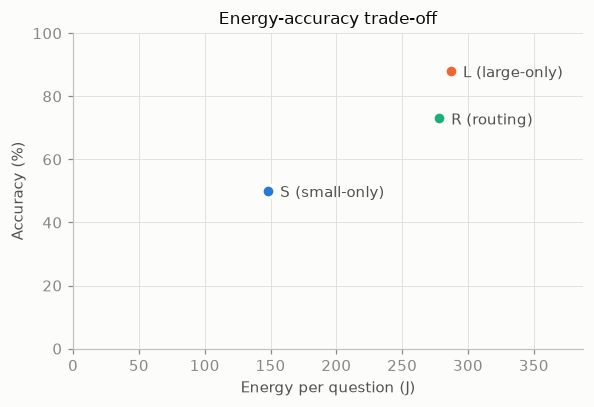

In [6]:
summary = runs.groupby("strategy", observed=True).agg(
    accuracy=("accuracy_pct", "mean"), energy=("energy_per_query_j", "mean"))
fig, ax = plt.subplots(figsize=(5.5, 3.8))

for strategy, row in summary.iterrows():
    ax.scatter(row["energy"], row["accuracy"], s=70, color=style.COLORS[strategy], zorder=3,
               edgecolor="#fcfcfb", linewidth=2)
    ax.annotate(style.label(strategy), (row["energy"], row["accuracy"]), xytext=(8, -4),
                textcoords="offset points", color=style.SECONDARY)
    
ax.set_xlabel("Energy per question (J)")
ax.set_ylabel("Accuracy (%)")
ax.set_xlim(0, summary["energy"].max() * 1.35)
ax.set_ylim(0, 100)
ax.set_title("Energy-accuracy trade-off")

plt.tight_layout()

## 4.3 Why does routing save so little energy?

This section is for interpretation. It looks at:

- **The routing decisions on the 100 experiment questions**, compared to what each model
  actually answered under S and L.
- **What R would cost if it just combined the two models' costs**, compared with what
  R actually used.

In [7]:
from sklearn.metrics import roc_auc_score

routed = data.load_queries("run_2_repetition_0").set_index("qid")
decisions = pd.DataFrame({"routed_to": routed["model"], "small_correct": answers["S"],
                          "large_correct": answers["L"]})

display(pd.crosstab(decisions["routed_to"], [decisions["small_correct"], decisions["large_correct"]],
                    rownames=["routed to"], colnames=["S correct", "L correct"]))

print(f"router AUC on the experiment questions: {roc_auc_score(answers['S'], routed['p_small_correct']):.2f}"
      " (0.5 = chance)")

per_question = runs.groupby("strategy", observed=True)["energy_per_query_j"].mean()
share_large = (routed["model"] == "large").mean()
mix = share_large * per_question["L"] + (1 - share_large) * per_question["S"]

print(f"weighted mix of S and L costs: {mix:.0f} J/question; measured R: {per_question['R']:.0f} J/question")

S correct  0      1    
L correct  0   1  0   1
routed to              
large      8  25  2  31
small      2  15  0  17

router AUC on the experiment questions: 0.45 (0.5 = chance)
weighted mix of S and L costs: 240 J/question; measured R: 278 J/question


**Notes**

- **Accuracy.** L is right on 88 questions, R on 73, S on 50.
  - All three strategies differ (Cochran's Q p ≈ 4·10⁻¹²), and so does every pair (exact
    McNemar p < 10⁻⁴).
  - R − L = −15 pp, 95% CI [−22, −8]. This is the **accuracy cost** of routing.
  - R is never right where L is wrong: its correct answers are a subset of L's.
  - The report deliberately makes no non-inferiority claim (Section 4.5).
- **Routing barely saves energy. The reasin is (probably) not the router:**
  - R sends 66% of questions to the large model, so most of the work is the same as under L.
  - Under R, both models are loaded and both GPUs are active, while the per-run baseline
    (the CPU's ~98 W) is paid for the whole run time.
  - The "weighted mix" line estimates R's cost if each question simply cost what it costs
    under S or L: 240 J. Measured R is 278 J, about 38 J per question more.
  - A likely part of that extra: under R both GPUs hold a model all the time. The 2B
    model's GPU averages 48 W under R at only 18% utilization, versus 12–15 W for an
    empty GPU (notebook 1). That's an interpretation to check, not a finding.
- **On these 100 questions, the router does no better than chance.** Its AUC is 0.45;
  0.5 means it can't tell easy questions from hard ones.
  - Of the 34 questions it sends to the small model, the small model gets 17 right: 50%,
    exactly its overall rate.
  - 15 of those 34 are questions L would have answered correctly. That is precisely the
    15 pp accuracy loss.
  - Worth comparing with the router's holdout accuracy from training: a router that worked
    on the train split but not here would point to overfitting, or to question text
    simply saying little about difficulty.

## 4.4 The router on the full test split

The 100 experiment questions are too few to judge the router: the AUC of 4.3 has a wide confidence
interval. Both models' answers to all 1319 GSM8K test questions are in `data/labels/test_{small,large}.jsonl`,
so the saved router is scored on all of them, with its experiment threshold.

These labels were not produced on the testbed (see `scripts/plot_router_test_split.py`), so on the
100 experiment questions they differ slightly from the measured answers. All numbers in this
section use these labels, also the 100-question column, so the two columns are comparable.


In [8]:
import json
import sys
import joblib

sys.path.insert(0, str(data.EXPERIMENT_DIR.parents[2] / "llm-routing"))
import config

def test_labels(model):
    rows = sorted(map(json.loads, open(config.REPO_ROOT / "data" / "labels" / f"test_{model}.jsonl")), key=lambda r: r["qid"])
    return np.array([r["correct"] for r in rows])

questions = [json.loads(line)["question"] for line in open(config.REPO_ROOT / "data" / "dataset" / "test.jsonl")]
small_ok, large_ok = test_labels("small"), test_labels("large")
router = joblib.load(config.ROUTER_FILE)
p_small = router.predict_proba(questions)[:, list(router.classes_).index(1)]
to_small = p_small > config.ROUTER_THRESHOLD
experiment_qids = answers.index.to_numpy()

def router_summary(qids):
    boot = []
    for _ in range(5_000):
        sample = rng.choice(qids, len(qids))
        if 0 < small_ok[sample].sum() < len(sample):
            boot.append(roc_auc_score(small_ok[sample], p_small[sample]))
    share_small = to_small[qids].mean()
    return {
        "questions": len(qids),
        "AUC": roc_auc_score(small_ok[qids], p_small[qids]),
        "AUC 95% CI": np.percentile(boot, [2.5, 97.5]).round(3),
        "sent to small (%)": 100 * share_small,
        "S accuracy (%)": 100 * small_ok[qids].mean(),
        "S accuracy on questions sent to small (%)": 100 * small_ok[qids][to_small[qids]].mean(),
        "L accuracy (%)": 100 * large_ok[qids].mean(),
        "R accuracy (%)": 100 * np.where(to_small, small_ok, large_ok)[qids].mean(),
        "random routing, same share (%)": 100 * (share_small * small_ok[qids].mean()
                                                 + (1 - share_small) * large_ok[qids].mean()),
    }

pd.DataFrame({"full test split": router_summary(np.arange(len(questions))),
              "experiment questions": router_summary(experiment_qids)})


,full test split,experiment questions
questions,1319,100
AUC,0.618,0.476
AUC 95% CI,"[0.587, 0.648]","[0.362, 0.59]"
sent to small (%),42.456,34.0
S accuracy (%),52.464,51.0
S accuracy on questions sent to small (%),63.214,52.941
L accuracy (%),87.642,93.0
R accuracy (%),74.678,78.0
"random routing, same share (%)",72.707,78.72


**Notes**

- **On the full test split the router is better than chance, but weak.** AUC 0.62, with a
  95% CI that excludes 0.5. The questions it sends to the small model are easier (the small model
  solves 63% of them, against 52.5% overall).
- **It gains little over random routing:** 74.7% accuracy against 72.7% for sending the same share
  to the small model at random (also visible in `data/analysis/figures/router_test_split.png`).
- **The 100 experiment questions were an unlucky sample for the router.** Their AUC interval
  includes 0.5 and values well below it, and on them routing does slightly worse than random (78% vs 78.7%), so "no better than chance" in 4.3 holds for that sample only, not
  for the router in general.
- This does not change the energy conclusion: a weak router still sends most questions to the large
  model, and R still pays for keeping both models loaded.
